# Group Members: Maheen Shahid , Hoor-ul-ain Wajid
# Program:Data Science
# Course:Data Visualization
# Submitted To:Sir rizwan

# Project Title:Flight Delay Prediction and Visualization

# Load Libraries

In [2]:
import shap
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
import plotly.graph_objects as go
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load Data

In [3]:
df=pd.read_csv("flights_sample_3m.csv")
df.head()

,FL_DATE,AIRLINE,AIRLINE_DOT,AIRLINE_CODE,DOT_CODE,FL_NUMBER,ORIGIN,ORIGIN_CITY,DEST,DEST_CITY,...,DIVERTED,CRS_ELAPSED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,DELAY_DUE_CARRIER,DELAY_DUE_WEATHER,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT
0,2019-01-09,United Air Lines Inc.,United Air Lines Inc.: UA,UA,19977,1562,FLL,"Fort Lauderdale, FL",EWR,"Newark, NJ",...,0.0,186.0,176.0,153.0,1065.0,NaN,NaN,NaN,NaN,NaN
1,2022-11-19,Delta Air Lines Inc.,Delta Air Lines Inc.: DL,DL,19790,1149,MSP,"Minneapolis, MN",SEA,"Seattle, WA",...,0.0,235.0,236.0,189.0,1399.0,NaN,NaN,NaN,NaN,NaN
2,2022-07-22,United Air Lines Inc.,United Air Lines Inc.: UA,UA,19977,459,DEN,"Denver, CO",MSP,"Minneapolis, MN",...,0.0,118.0,112.0,87.0,680.0,NaN,NaN,NaN,NaN,NaN
3,2023-03-06,Delta Air Lines Inc.,Delta Air Lines Inc.: DL,DL,19790,2295,MSP,"Minneapolis, MN",SFO,"San Francisco, CA",...,0.0,260.0,285.0,249.0,1589.0,0.0,0.0,24.0,0.0,0.0
4,2020-02-23,Spirit Air Lines,Spirit Air Lines: NK,NK,20416,407,MCO,"Orlando, FL",DFW,"Dallas/Fort Worth, TX",...,0.0,181.0,182.0,153.0,985.0,NaN,NaN,NaN,NaN,NaN


# Information About Data

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000000 entries, 0 to 2999999
Data columns (total 32 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   FL_DATE                  object 
 1   AIRLINE                  object 
 2   AIRLINE_DOT              object 
 3   AIRLINE_CODE             object 
 4   DOT_CODE                 int64  
 5   FL_NUMBER                int64  
 6   ORIGIN                   object 
 7   ORIGIN_CITY              object 
 8   DEST                     object 
 9   DEST_CITY                object 
 10  CRS_DEP_TIME             int64  
 11  DEP_TIME                 float64
 12  DEP_DELAY                float64
 13  TAXI_OUT                 float64
 14  WHEELS_OFF               float64
 15  WHEELS_ON                float64
 16  TAXI_IN                  float64
 17  CRS_ARR_TIME             int64  
 18  ARR_TIME                 float64
 19  ARR_DELAY                float64
 20  CANCELLED                float64
 21  CANCELLA

# Missing Values

In [5]:
df.isnull().sum()

FL_DATE                          0
AIRLINE                          0
AIRLINE_DOT                      0
AIRLINE_CODE                     0
DOT_CODE                         0
FL_NUMBER                        0
ORIGIN                           0
ORIGIN_CITY                      0
DEST                             0
DEST_CITY                        0
CRS_DEP_TIME                     0
DEP_TIME                     77615
DEP_DELAY                    77644
TAXI_OUT                     78806
WHEELS_OFF                   78806
WHEELS_ON                    79944
TAXI_IN                      79944
CRS_ARR_TIME                     0
ARR_TIME                     79942
ARR_DELAY                    86198
CANCELLED                        0
CANCELLATION_CODE          2920860
DIVERTED                         0
CRS_ELAPSED_TIME                14
ELAPSED_TIME                 86198
AIR_TIME                     86198
DISTANCE                         0
DELAY_DUE_CARRIER          2466137
DELAY_DUE_WEATHER   

### The delay values are mostly filled with NAN, so it can be assumed that for those filghts with no delay the values are filled as NAN and incase of delay numerical values is entered. So we weill replace NAN with 0 to show no delay.

In [6]:
delay = ['DELAY_DUE_LATE_AIRCRAFT', 'DELAY_DUE_SECURITY', 'DELAY_DUE_NAS',
              'DELAY_DUE_WEATHER', 'DELAY_DUE_CARRIER']

df[delay] = df[delay].fillna(0)

### Droping Canccellation Code as it is of string type and can not be filled. More than 90% of its values are missinf. So we will drop it.

In [7]:
df=df.drop('CANCELLATION_CODE', inplace=False, axis=1)

### Using simple imputor to fill in missing values with the mean for data witth less missing values

In [8]:
columns =  df.columns[df.isna().any()].tolist()
columns

['DEP_TIME',
 'DEP_DELAY',
 'TAXI_OUT',
 'WHEELS_OFF',
 'WHEELS_ON',
 'TAXI_IN',
 'ARR_TIME',
 'ARR_DELAY',
 'CRS_ELAPSED_TIME',
 'ELAPSED_TIME',
 'AIR_TIME']

In [9]:
imp = SimpleImputer(strategy='mean')  
df[columns] = imp.fit_transform(df[columns])

In [10]:
df.isnull().sum()

FL_DATE                    0
AIRLINE                    0
AIRLINE_DOT                0
AIRLINE_CODE               0
DOT_CODE                   0
FL_NUMBER                  0
ORIGIN                     0
ORIGIN_CITY                0
DEST                       0
DEST_CITY                  0
CRS_DEP_TIME               0
DEP_TIME                   0
DEP_DELAY                  0
TAXI_OUT                   0
WHEELS_OFF                 0
WHEELS_ON                  0
TAXI_IN                    0
CRS_ARR_TIME               0
ARR_TIME                   0
ARR_DELAY                  0
CANCELLED                  0
DIVERTED                   0
CRS_ELAPSED_TIME           0
ELAPSED_TIME               0
AIR_TIME                   0
DISTANCE                   0
DELAY_DUE_CARRIER          0
DELAY_DUE_WEATHER          0
DELAY_DUE_NAS              0
DELAY_DUE_SECURITY         0
DELAY_DUE_LATE_AIRCRAFT    0
dtype: int64

# Check for duplicates

In [11]:
df.duplicated().sum()

0

In [12]:
def save_data(df, target_path="output.csv"):
    """
    Save the DataFrame to a CSV file.
    """
    df.to_csv(target_path, index=False, encoding='utf-8-sig')
    print(f"Data saved to {target_path}")
save_data(df, target_path="fkight.csv")

Data saved to fkight.csv


# Correlation

In [13]:
num_df = df.select_dtypes(include=['number'])


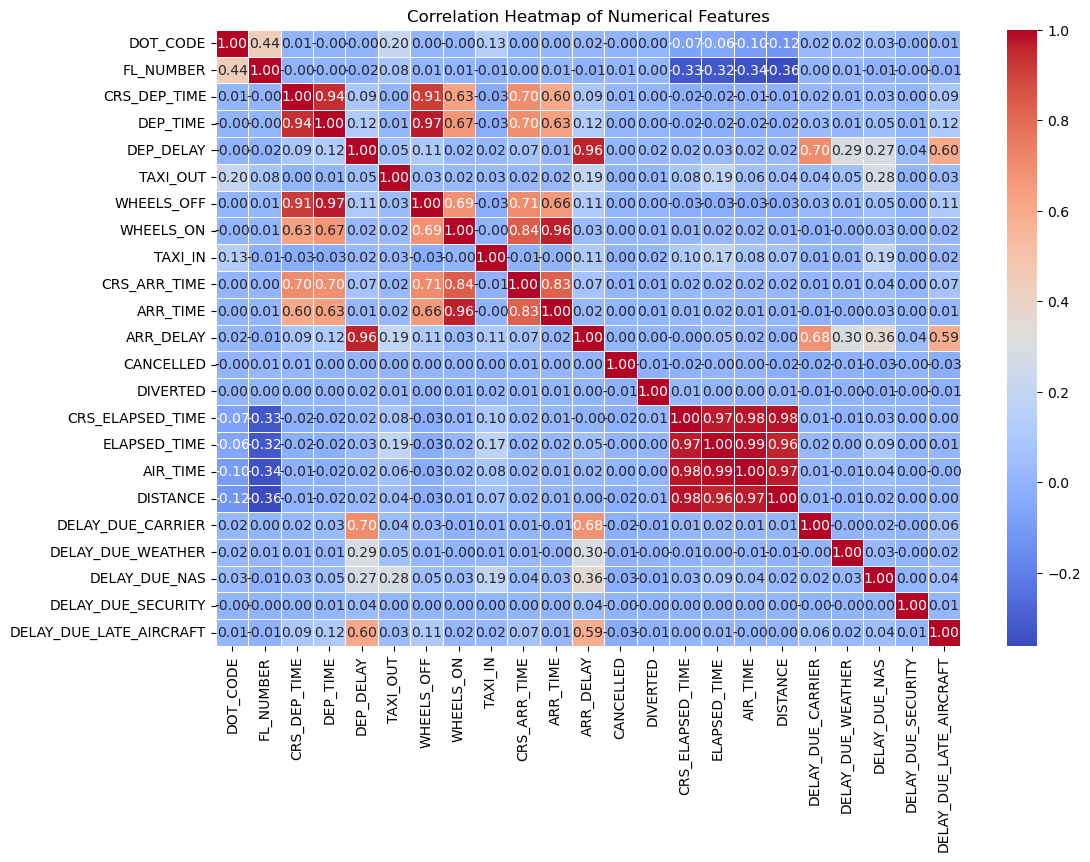

In [14]:
corr = num_df.corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

### **Key Features and Observations**
- **High Positive Correlations**:
  - **DEP_TIME** and **ARR_TIME**: Strong correlation (0.99), indicating that as departure times increase, arrival times also increase.
  - **ARR_DELAY** and **ARR_TIME**: High correlation (0.96), suggesting that delayed arrivals correspond to later arrival times.
  - **WHEELS_OFF** and **WHEELS_ON**: Strong positive correlation (0.84), indicating that takeoff time is closely related to landing time.

- **Moderate Positive Correlations**:
  - **DEP_DELAY** and **ARR_DELAY** (0.67): Delays in departure tend to result in delays in arrival.
  - **ELAPSED_TIME** and both **DEP_TIME** and **ARR_TIME**: Suggests that total time in the air is associated with the times of departure and arrival.
  
- **Negative Correlations**:
  - **CANCELLED** and other features: The cancelled flights show a negative correlation with delays and elapsed time, confirming that cancelled flights do not have associated delays.
  - **DISTANCE** has a moderate negative correlation (-0.12) with **ELAPSED_TIME**, indicating that greater distances do not correlate with longer elapsed times as might be expected.

### **Implications for Analysis**
- **Flight Timing**: High correlation between departure and arrival times underscores the importance of timing in airline operations.
- **Delay Impact**: Understanding the correlation between delays can help airlines strategize on mitigating factors contributing to both departures and arrivals.
- **Cancellation Analysis**: The clear negative correlation of cancellations with other operational metrics informs about the impacts of cancellations.



# Histogram: Distribution of Arrival Delay

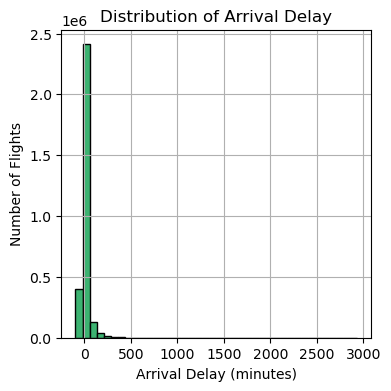

In [15]:
plt.figure(figsize=(4,4))
plt.hist(df['ARR_DELAY'], bins=40, color='mediumseagreen', edgecolor='black')
plt.title('Distribution of Arrival Delay')
plt.xlabel('Arrival Delay (minutes)')
plt.ylabel('Number of Flights')
plt.grid(True)
plt.show()

# Analysis of Flight Arrival Delay Distribution

The histogram shows the distribution of flight arrival delays. Most flights experience minimal delays, clustering near 0 minutes, while the number of flights significantly decreases as delays increase. 
Although the graph extends to 3000 minutes, long delays are rare, indicating that while most flights are punctual, a small number face significant delays.



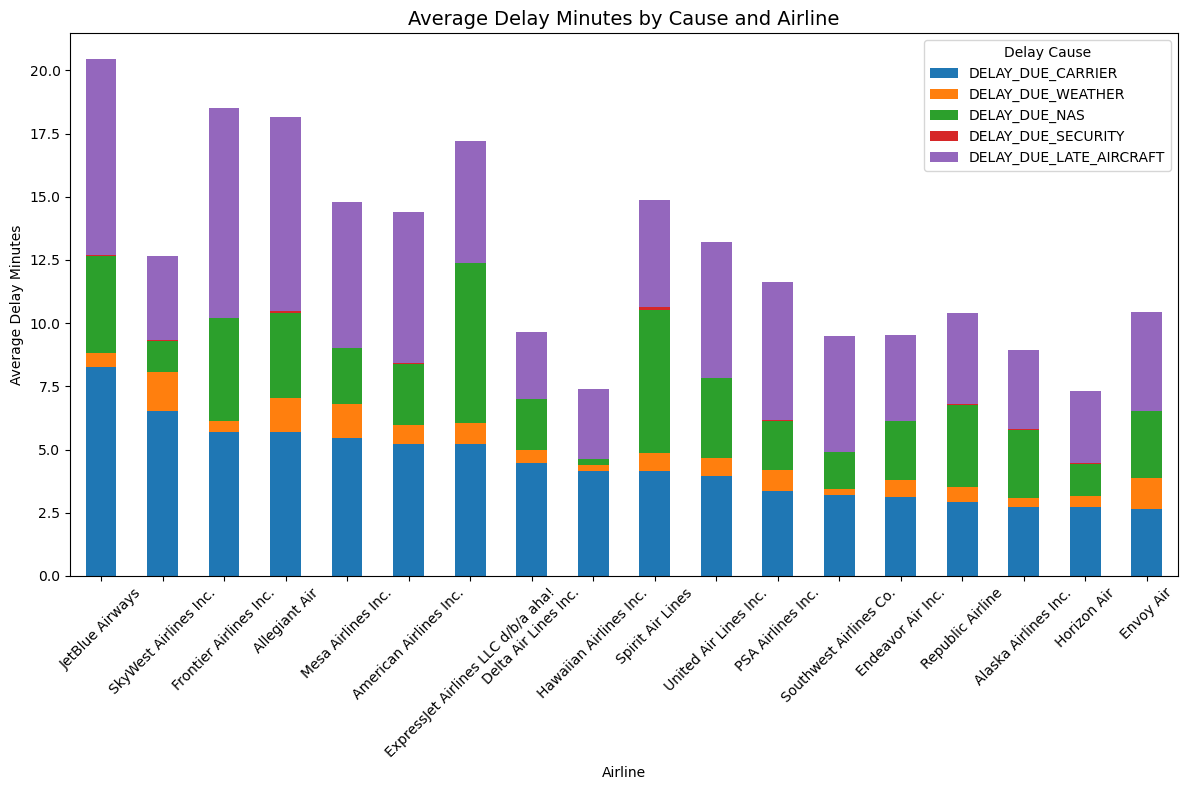

In [16]:
# 1. Stacked Bar Chart of Delay Causes by Airline
plt.figure(figsize=(12, 8))
delay_cols = ['DELAY_DUE_CARRIER', 'DELAY_DUE_WEATHER', 'DELAY_DUE_NAS', 
              'DELAY_DUE_SECURITY', 'DELAY_DUE_LATE_AIRCRAFT']
delay_by_airline = df.groupby('AIRLINE')[delay_cols].mean().sort_values('DELAY_DUE_CARRIER', ascending=False)
delay_by_airline.plot(kind='bar', stacked=True, ax=plt.gca())
plt.title('Average Delay Minutes by Cause and Airline', fontsize=14)
plt.ylabel('Average Delay Minutes')
plt.xlabel('Airline')
plt.xticks(rotation=45)
plt.legend(title='Delay Cause')
plt.tight_layout()
plt.show()

The graph displays the average delay minutes for various airlines, categorized by the cause of delay. Each airline is represented with a stacked bar, showing different delay causes:

## X-Axis (Airlines): 
Lists the airlines included in the analysis.

## Y-Axis (Average Delay Minutes):
Indicates the average minutes of delay experienced by flights for each airline.

# Key Observations:
### Color Coding:
Each color represents a specific delay cause (e.g., carrier, weather, NAS, security, late aircraft).

### Trends:
Some airlines experience higher average delays due to specific causes, while others may have more balanced delays across categories.

### Comparison:
This allows for easy comparison between airlines regarding which factors contribute most to delays.

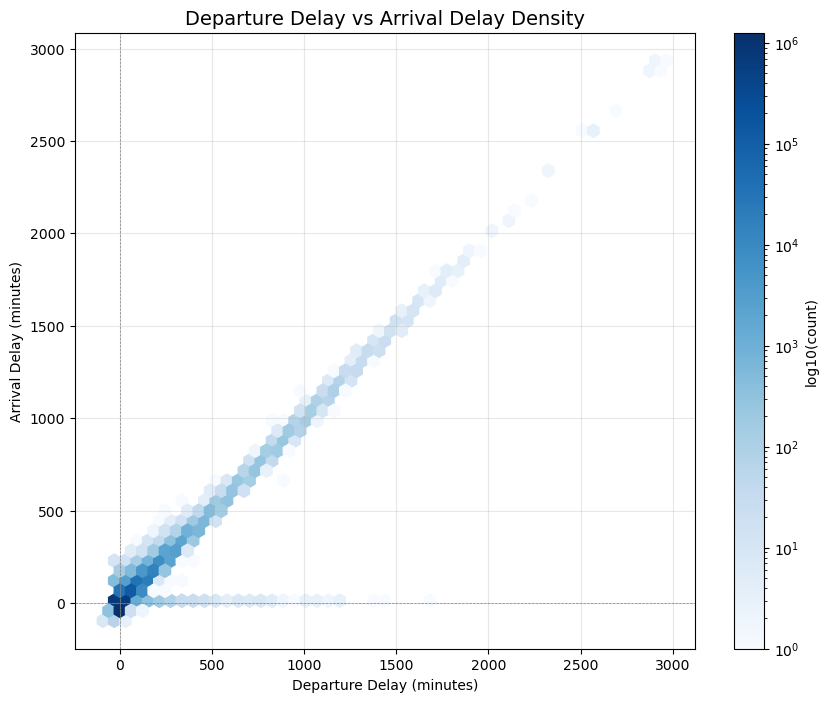

In [17]:
# 2. Hexbin Plot of Departure Delay vs Arrival Delay
plt.figure(figsize=(10, 8))
hb = plt.hexbin(df['DEP_DELAY'], df['ARR_DELAY'], gridsize=50, cmap='Blues', bins='log', mincnt=1)
plt.colorbar(hb, label='log10(count)')
plt.title('Departure Delay vs Arrival Delay Density', fontsize=14)
plt.xlabel('Departure Delay (minutes)')
plt.ylabel('Arrival Delay (minutes)')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.5)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
plt.grid(True, alpha=0.3)
plt.show()

The graph shows the relationship between departure delays and arrival delays.

# Key Points:

## X-Axis: 
Departure delay in minutes.

## Y-Axis:
Arrival delay in minutes.

Density Color Gradient: Darker shades indicate higher counts of flights.
# Observations:

## Concentration of Points:
Most flights have minimal delays, clustering near the origin (0,0), suggesting that on-time departures are common.

## Increasing Delays:
As departure delays increase, there is a gradual increase in arrival delays, indicating a correlation between the two.

##Outliers:
Some flights show significant delays in both departure and arrival, which are represented by higher density in the upper right quadrant.

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


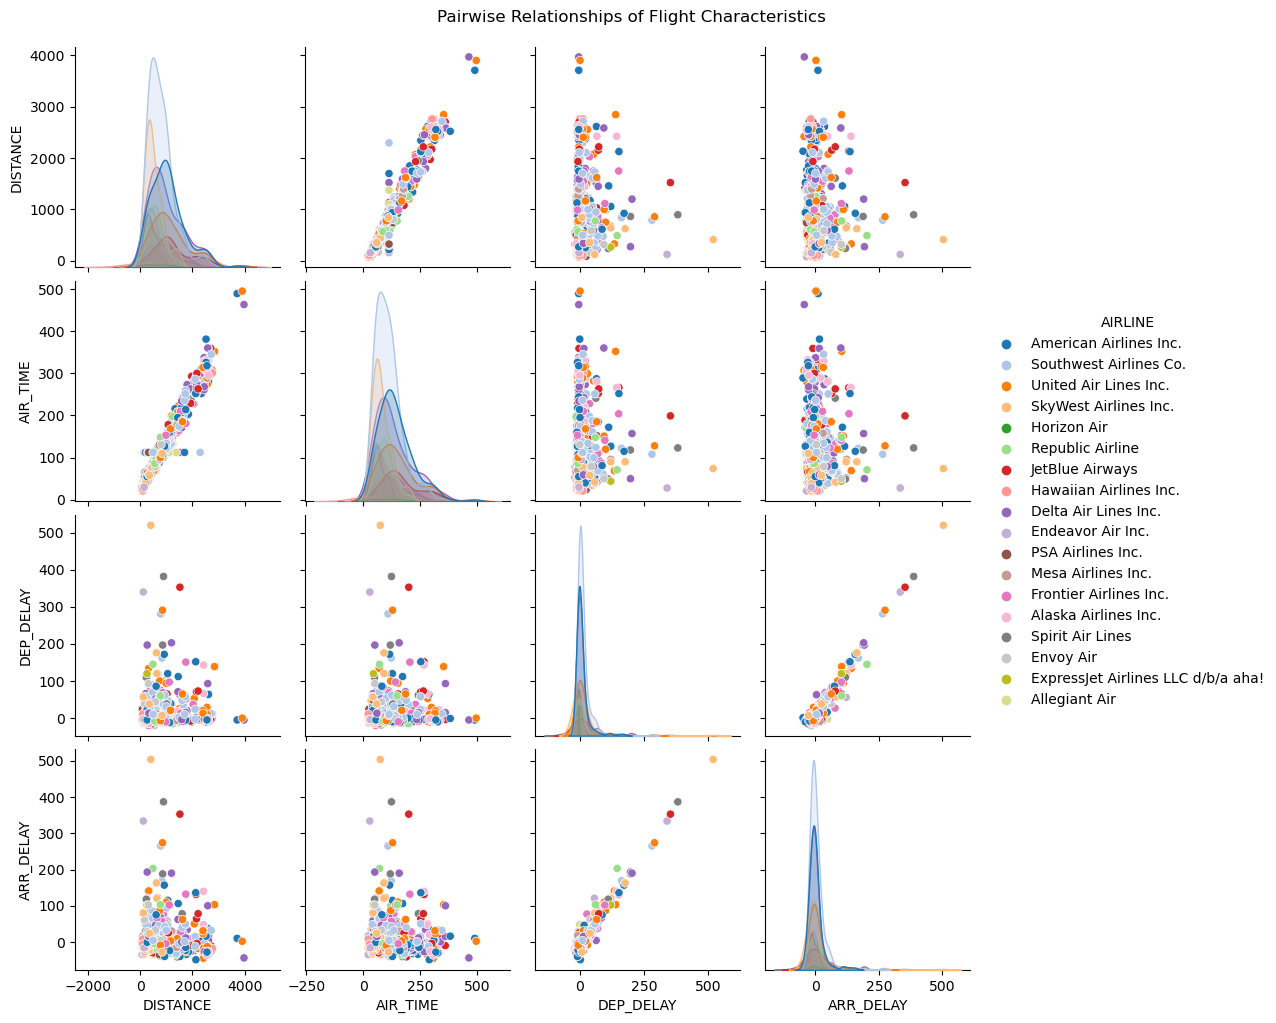

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


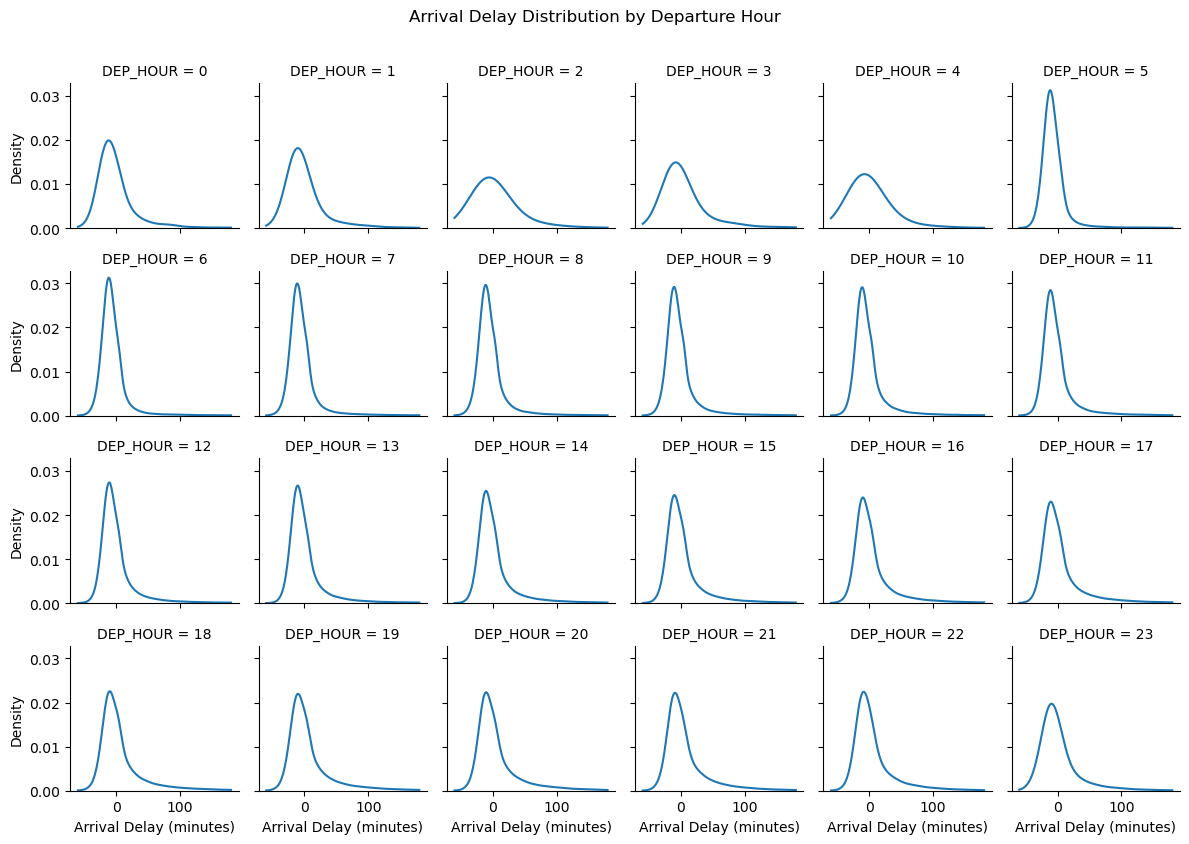

In [18]:
# 3. Pairplot of Flight Characteristics
sns.pairplot(df.sample(1000)[['DISTANCE', 'AIR_TIME', 'DEP_DELAY', 'ARR_DELAY', 'AIRLINE']], 
             hue='AIRLINE', diag_kind='kde', palette='tab20')
plt.suptitle('Pairwise Relationships of Flight Characteristics', y=1.02)
plt.show()

# 4. FacetGrid of Delay Causes by Time of Day
df['DEP_HOUR'] = df['CRS_DEP_TIME'] // 100
g = sns.FacetGrid(df, col='DEP_HOUR', col_wrap=6, height=2)
g.map(sns.kdeplot, 'ARR_DELAY', clip=(-60, 180))
g.fig.suptitle('Arrival Delay Distribution by Departure Hour', y=1.05)
g.set_axis_labels('Arrival Delay (minutes)', 'Density')
plt.show()

# Interpretation of the Graphs

## 1. Pairplot of Flight Characteristics
The pairplot shows relationships between flight distance, air time, departure delay, and arrival delay, colored by airline.

### Key Points:

#### Distance vs. Air Time: 
A clear positive correlation indicates that longer flights typically take more time.

#### Departure vs. Arrival Delay:
Strong correlation suggests that delays at departure lead to similar delays upon arrival.

#### Airline Comparison: 
Different colors represent airlines, allowing for easy comparison of their performance.

## 2. Arrival Delay Distribution by Departure Hour
This graph features density plots of arrival delays based on the hour of departure.

### Key Points:

#### Peak at 0 Minutes:
Most flights arrive on time or with minor delays.

#### Variability:
Delay distributions vary by departure hour, with some hours showing wider spreads and more significant delays, particularly during peak travel times.

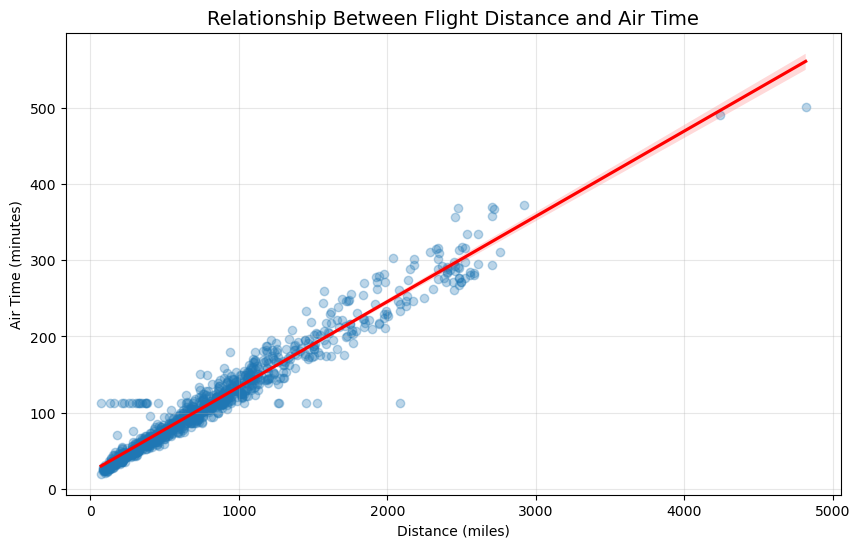

In [19]:
# 5. Regression Plot of Distance vs Air Time
plt.figure(figsize=(10, 6))
sns.regplot(x='DISTANCE', y='AIR_TIME', data=df.sample(1000), 
            scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Relationship Between Flight Distance and Air Time', fontsize=14)
plt.xlabel('Distance (miles)')
plt.ylabel('Air Time (minutes)')
plt.grid(True, alpha=0.3)
plt.show()

The graph illustrates the relationship between flight distance and air time.

# Key Points:
## X-Axis: 
Flight distance in miles.

## Y-Axis:
Air time in minutes.

## Trend Line:
The red line indicates a positive correlation between distance and air time.

## Observations:
As flight distance increases, air time also increases, suggesting that longer flights take more time.
The data points are closely aligned with the trend line, indicating a strong linear relationship.

In [20]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Interactive Scatter Plot of Delays
fig = px.scatter(df.sample(1000), x='DEP_DELAY', y='ARR_DELAY', 
                 color='AIRLINE', hover_data=['ORIGIN_CITY', 'DEST_CITY'],
                 title='Departure vs Arrival Delays')
fig.update_layout(xaxis_title='Departure Delay (minutes)',
                 yaxis_title='Arrival Delay (minutes)')
fig.show()

## Interpretation of the Graph
The scatter plot illustrates the relationship between departure delays and arrival delays, with data points colored by airline.

## Key Points:

### Positive Correlation: 
There is a clear trend where longer departure delays generally correspond to longer arrival delays, indicating that delays at departure often lead to similar delays upon arrival.

### Airline Variation: 
Different colors represent various airlines, allowing for comparison. Some airlines show more variability in delays than others.
### Outliers:
A few data points exhibit significantly high delays, particularly in arrival, suggesting certain flights experience extreme delays.

In [21]:
# 3. Animated Bar Chart of Delays Over Time
df['FL_DATE'] = pd.to_datetime(df['FL_DATE'])
monthly_delays = df.groupby([df['FL_DATE'].dt.to_period('M'), 'AIRLINE'])['ARR_DELAY'].mean().reset_index()
monthly_delays['FL_DATE'] = monthly_delays['FL_DATE'].astype(str)

fig = px.bar(monthly_delays, x='AIRLINE', y='ARR_DELAY', 
             animation_frame='FL_DATE', color='AIRLINE',
             title='Average Arrival Delays by Airline Over Time')
fig.update_layout(yaxis_title='Average Arrival Delay (minutes)')
fig.show()

## Interpretation of the Graph
The animated bar chart displays average arrival delays by airline over time, illustrating trends across different months.

## Key Points:

### Monthly Trends:
The animation allows viewers to observe how average arrival delays change month by month for each airline.

## Airline Comparison:
Different airlines are color-coded, making it easy to compare their performance. Some airlines consistently show higher delays, while others maintain lower averages.

## Significant Variations:
Certain months exhibit spikes or drops in delays for specific airlines, indicating potential issues or improvements in performance.

# Create New features

In [22]:
def feature_engineer(df):
    # Convert date
    df['FL_DATE'] = pd.to_datetime(df['FL_DATE'])
    df['DAY_OF_WEEK'] = df['FL_DATE'].dt.day_name()
    
    # Route feature (optional, could help)
    df['ROUTE'] = df['ORIGIN'] + '-' + df['DEST']
    
    # Whether flight was diverted (already present)
    df['IS_DIVERTED'] = (df['DIVERTED'] == 1).astype(int)
    df['DEP_HOUR'] = df['DEP_TIME'] // 100  # Create an hour of departure
    df['ARR_HOUR'] = df['ARR_TIME'] // 100  # Arrival hour
    
    return df

# Apply feature engineering
df = feature_engineer(df)

In [23]:
# Create DEPARTURE_PERIOD (based on DEP_TIME)
def get_departure_period(dep_time):
    if np.isnan(dep_time):
        return 'Unknown'
    if 500 <= dep_time < 1200:
        return 'Morning'
    elif 1200 <= dep_time < 1700:
        return 'Afternoon'
    elif 1700 <= dep_time < 2100:
        return 'Evening'
    else:
        return 'Night'

df['DEPARTURE_PERIOD'] = df['DEP_TIME'].apply(get_departure_period)

# Encoding Categorical Feature

In [24]:
categorical_cols = ['AIRLINE', 'ORIGIN', 'DEST', 'DAY_OF_WEEK', 'ROUTE', 'DEPARTURE_PERIOD']

# Apply Label Encoding
le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))

# Selecting Features

In [25]:
feature_cols = ['DEP_DELAY', 'TAXI_OUT', 'DISTANCE', 'AIR_TIME', 
                'AIRLINE', 'ORIGIN', 'DEST', 'DAY_OF_WEEK', 'ROUTE', 'DEPARTURE_PERIOD']

X = df[feature_cols]
y = df['ARR_DELAY']

# Train Test Split

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model Training

In [27]:
model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=7,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=-1, num_parallel_tree=None, ...)

# Model Evaluation

In [28]:
y_pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 6.7388607600323125
MSE: 323.79704997574805
RMSE: 17.99436161623268
R2 Score: 0.874079578077249


In [29]:
df.isnull().sum()

FL_DATE                    0
AIRLINE                    0
AIRLINE_DOT                0
AIRLINE_CODE               0
DOT_CODE                   0
FL_NUMBER                  0
ORIGIN                     0
ORIGIN_CITY                0
DEST                       0
DEST_CITY                  0
CRS_DEP_TIME               0
DEP_TIME                   0
DEP_DELAY                  0
TAXI_OUT                   0
WHEELS_OFF                 0
WHEELS_ON                  0
TAXI_IN                    0
CRS_ARR_TIME               0
ARR_TIME                   0
ARR_DELAY                  0
CANCELLED                  0
DIVERTED                   0
CRS_ELAPSED_TIME           0
ELAPSED_TIME               0
AIR_TIME                   0
DISTANCE                   0
DELAY_DUE_CARRIER          0
DELAY_DUE_WEATHER          0
DELAY_DUE_NAS              0
DELAY_DUE_SECURITY         0
DELAY_DUE_LATE_AIRCRAFT    0
DEP_HOUR                   0
DAY_OF_WEEK                0
ROUTE                      0
IS_DIVERTED   

# SHAP

In [30]:
explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_test)

100%|===================| 599963/600000 [215:37<00:00]         

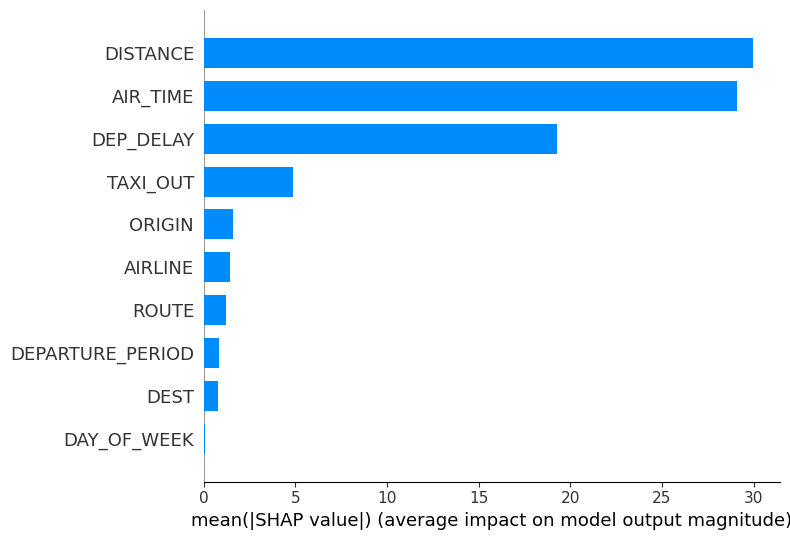

In [31]:
# SHAP Summary Plot (Feature importance)
shap.summary_plot(shap_values, X_test, plot_type="bar")

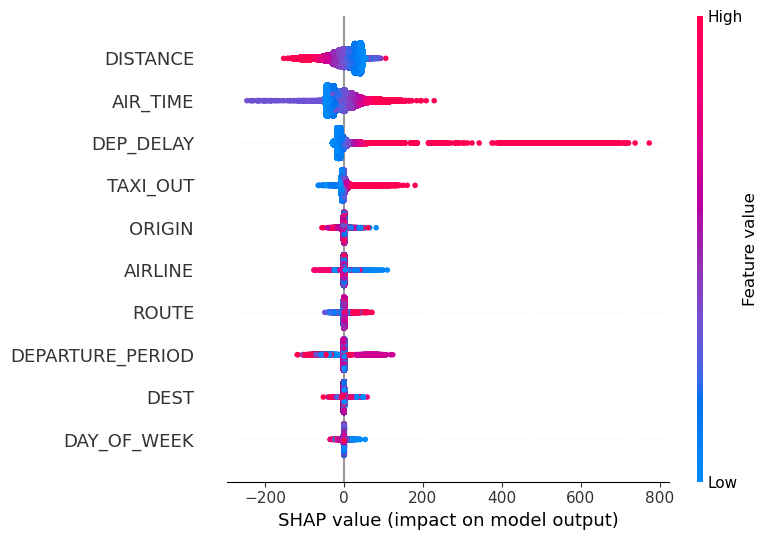

In [32]:
shap.summary_plot(shap_values, X_test)

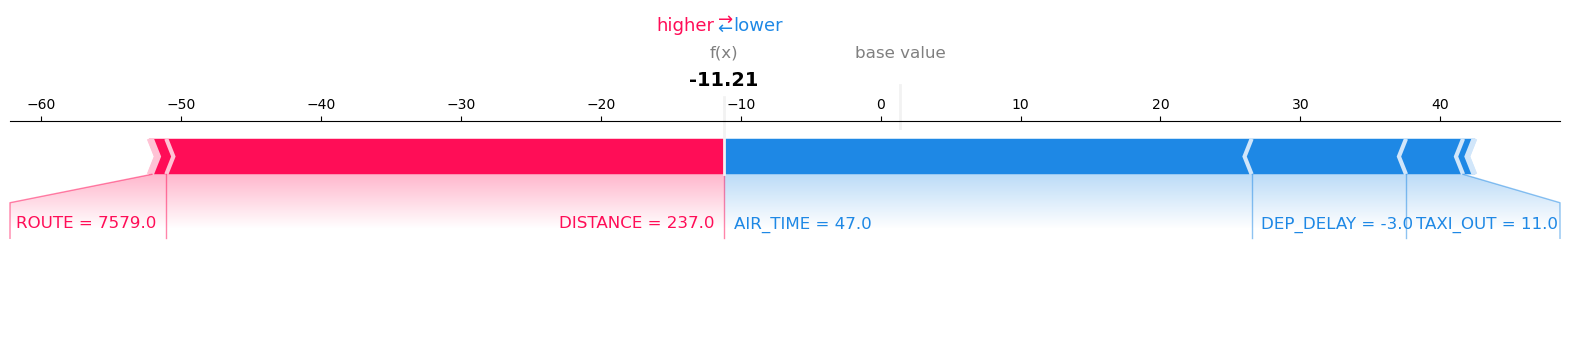

In [33]:
# 3. SHAP Force Plot (for a single prediction)
# Pick a random row
i = 10  # You can change this index to any test sample
shap.force_plot(explainer.expected_value, shap_values.values[i,:], X_test.iloc[i,:], matplotlib=True)
plt.show()

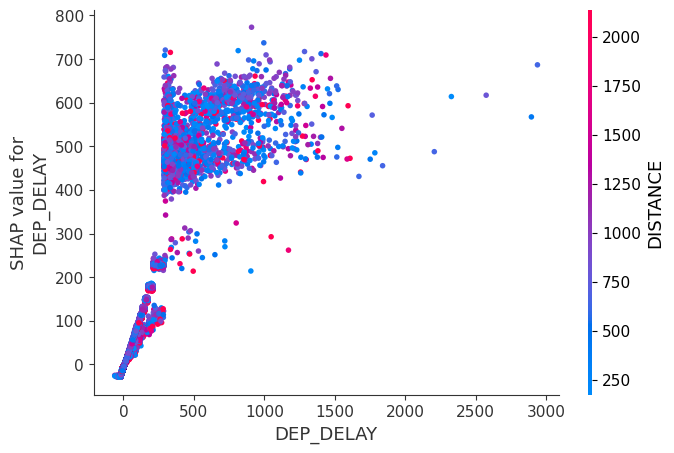

In [34]:
# 4. SHAP Dependence Plot (for a feature)
# Example for DEP_DELAY
shap.dependence_plot('DEP_DELAY', shap_values.values, X_test)
plt.show()

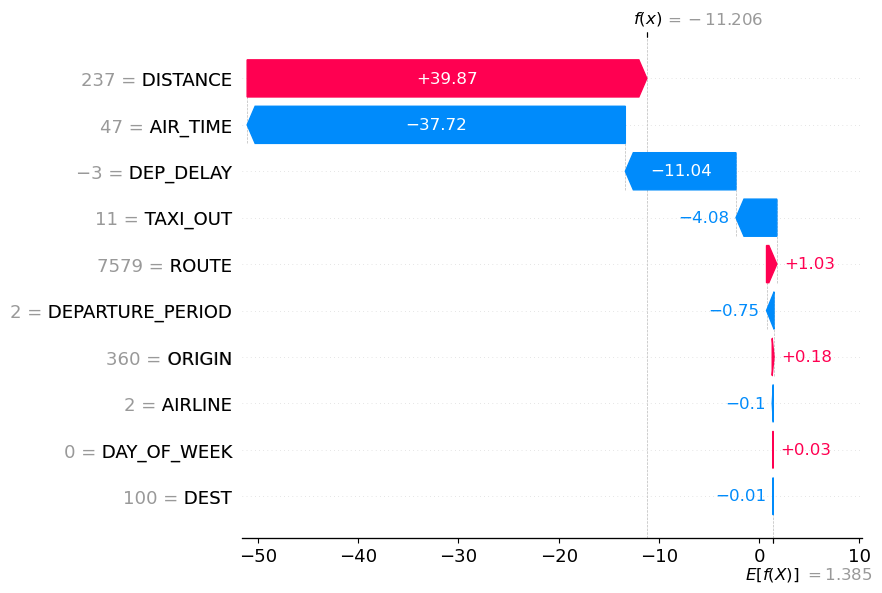

In [35]:
# 5. SHAP Waterfall Plot (for a single prediction)
# Again using the same sample i = 10
shap.plots.waterfall(shap_values[i])
plt.show()